# Linear and Polynomial Regression

**Tasks**
1. Load the data and shape it (X = predictors, y = target)
2. Train/test split
3. Linear regression, polynomial regression (degree 2 and 3)
4. Metrics (RMSE, R²)
5. Predicted vs actual scatter plots

Part A data: UK local-authority population by age band (`sexDensitiesMale.csv`, `sexDensitiesFemale.csv`). Part B data: Life Expectancy (WHO) from Kaggle.
**Part A** is worked for you. **Part B** repeats the same steps on the Life Expectancy data.

## Setup

In [1]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

DATA_DIR = "."
print("Ready")

Ready


# Part A: worked example
**Question:** can the share of people aged over 61 in a local authority be predicted from the shares of younger age groups?

## A1. Load the data

In [3]:
male = pd.read_csv(f"{DATA_DIR}/sexDensitiesMale.csv")
female = pd.read_csv(f"{DATA_DIR}/sexDensitiesFemale.csv")
ages = male.merge(female, on="CODE", suffixes=("_m", "_f"))

print("rows:", len(ages))
print(ages[["CODE", "Location_m", "AllAges_m", "<18_m", "26-30_m", ">61_m"]].head())

rows: 439
        CODE         Location_m  AllAges_m    <18_m  26-30_m    >61_m
0  K02000001     UNITED KINGDOM   31793752  7412279  2184056  6506753
1  K03000001      GREAT BRITAIN   30891041  7177668  2122744  6343126
2  K04000001  ENGLAND AND WALES   28294511  6617392  1948958  5793929
3  E92000001            ENGLAND   26773196  6274836  1854176  5441119
4  E12000001         NORTH EAST    1283216   286066    82491   281796


## A2. Clean and shape the data
The file mixes countries, regions, counties and local authorities. We keep **only local authority rows** (codes starting E06, E07, E08, E09, W06, S12, N09).

Then we turn counts into **percentages of each authority's population**, so large and small areas are comparable.

In [4]:
authority_codes = ("E06", "E07", "E08", "E09", "W06", "S12", "N09")
auth = ages[ages["CODE"].str.startswith(authority_codes)].reset_index(drop=True)
total = auth["AllAges_m"] + auth["AllAges_f"]

df = pd.DataFrame({"area": auth["Location_m"]})
df["pct_under18"] = 100 * (auth["<18_m"] + auth["<18_f"]) / total
df["pct_19_25"] = 100 * (auth["19-25_m"] + auth["19-25_f"]) / total
df["pct_26_30"] = 100 * (auth["26-30_m"] + auth["26-30_f"]) / total
df["pct_31_35"] = 100 * (auth["31-35_m"] + auth["31-35_f"]) / total
df["pct_35_45"] = 100 * (auth["35-45_m"] + auth["35-45_f"]) / total
df["pct_old"] = 100 * (auth[">61_m"] + auth[">61_f"]) / total

df = df.dropna().reset_index(drop=True)
print(df.head())
print("\nRows:", len(df))

             area  pct_under18  pct_19_25  pct_26_30  pct_31_35  pct_35_45  \
0   County Durham    20.563452   9.878074   5.771641   5.828616  12.043695   
1      Darlington    22.735771   7.604848   6.070212   6.167016  12.929095   
2      Hartlepool    22.843720   8.708284   6.447781   5.790042  11.838211   
3   Middlesbrough    24.203020  11.886227   7.014139   6.122816  11.480100   
4  Northumberland    20.069497   6.972439   5.133756   5.222683  11.705545   

     pct_old  
0  24.584905  
1  23.766454  
2  23.206610  
3  19.901667  
4  28.161285  

Rows: 390


In [5]:
feature_cols = ["pct_under18", "pct_19_25", "pct_26_30", "pct_31_35", "pct_35_45"]
X = df[feature_cols].values
y = df["pct_old"].values

print("X shape:", X.shape, "  y shape:", y.shape)

X shape: (390, 5)   y shape: (390,)


`pct_45_60` is left out on purpose: the age shares add up to 100%, so using all of them would give the model the answer by subtraction.

## A3. Train/test split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("train rows:", len(X_train), "  test rows:", len(X_test))

train rows: 292   test rows: 98


## A4. Linear regression baseline

In [7]:
lin = LinearRegression()
lin.fit(X_train, y_train)

y_pred_lin = lin.predict(X_test)
rmse_lin = math.sqrt(mean_squared_error(y_test, y_pred_lin))
r2_lin = r2_score(y_test, y_pred_lin)

print(f"Linear Regression - RMSE: {rmse_lin:.2f}, R²: {r2_lin:.3f}")
print("Coefficients:")
print(f"   pct_under18  {lin.coef_[0]:8.3f}")
print(f"   pct_19_25    {lin.coef_[1]:8.3f}")
print(f"   pct_26_30    {lin.coef_[2]:8.3f}")
print(f"   pct_31_35    {lin.coef_[3]:8.3f}")
print(f"   pct_35_45    {lin.coef_[4]:8.3f}")
print("Intercept:", round(lin.intercept_, 3))

Linear Regression - RMSE: 0.75, R²: 0.970
Coefficients:
   pct_under18    -0.778
   pct_19_25      -0.754
   pct_26_30      -1.139
   pct_31_35       0.231
   pct_35_45      -1.672
Intercept: 74.466


In [8]:
lin

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-0.78,-0.75,-1.14, 0.23,-1.67]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,74.47
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[55.1 ,41.68,28.01,12.71, 3.94]"


RMSE is the typical size of a miss, in the same units as y (percentage points). R² is the share of the variation the model explains (1 = perfect, 0 = no better than the average).

## A5. Polynomial regression (degree 2 and 3)
`PolynomialFeatures` adds squares and products of the features so the model can bend. `StandardScaler` puts all the columns on the same scale. We fit the training data, then apply the same steps to the test data.

### Degree 2

In [9]:
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_p2 = poly2.fit_transform(X_train)
X_test_p2 = poly2.transform(X_test)

scaler2 = StandardScaler()
X_train_s2 = scaler2.fit_transform(X_train_p2)
X_test_s2 = scaler2.transform(X_test_p2)

lin2 = LinearRegression()
lin2.fit(X_train_s2, y_train)
p2 = lin2.predict(X_test_s2)
print(f"Plain poly d=2 - RMSE: {math.sqrt(mean_squared_error(y_test, p2)):.2f}, R²: {r2_score(y_test, p2):.3f}")

Plain poly d=2 - RMSE: 0.67, R²: 0.976


### Degree 3

In [10]:
poly3 = PolynomialFeatures(degree=3, include_bias=False)
X_train_p3 = poly3.fit_transform(X_train)
X_test_p3 = poly3.transform(X_test)

scaler3 = StandardScaler()
X_train_s3 = scaler3.fit_transform(X_train_p3)
X_test_s3 = scaler3.transform(X_test_p3)

lin3 = LinearRegression()
lin3.fit(X_train_s3, y_train)
p3 = lin3.predict(X_test_s3)
print(f"Plain poly d=3 - RMSE: {math.sqrt(mean_squared_error(y_test, p3)):.2f}, R²: {r2_score(y_test, p3):.3f}")

Plain poly d=3 - RMSE: 1.00, R²: 0.947


## A6. Predicted vs actual

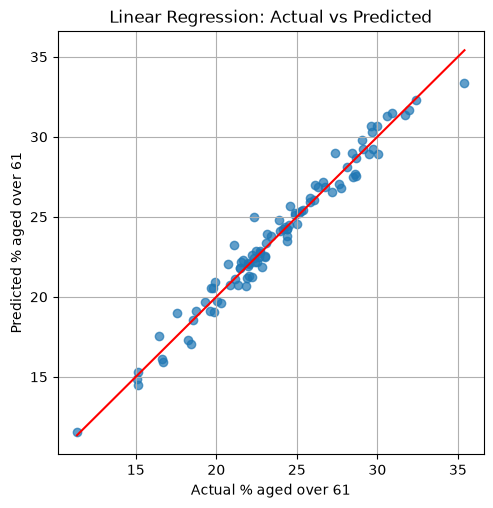

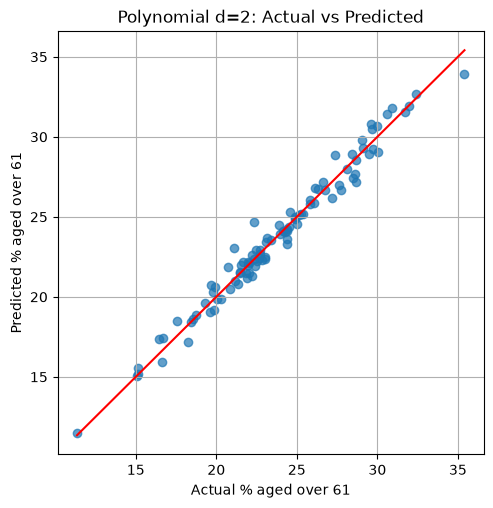

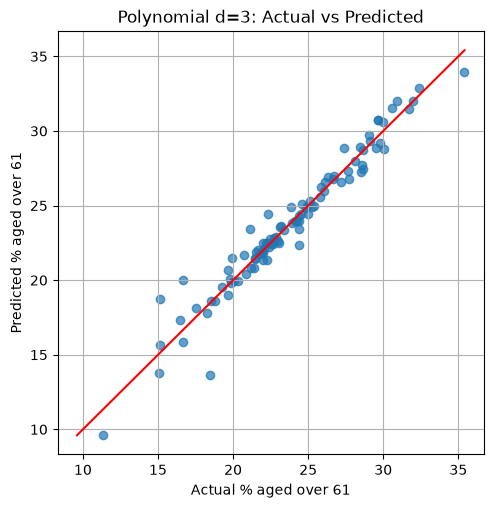

In [11]:
def plot_pred_vs_actual(y_true, y_pred, title):
    plt.figure(figsize=(5.5, 5.5))
    plt.scatter(y_true, y_pred, alpha=0.7)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    plt.plot(lims, lims, color="red")          # perfect predictions lie on this line
    plt.xlabel("Actual % aged over 61")
    plt.ylabel("Predicted % aged over 61")
    plt.title(title)
    plt.grid(True)
    plt.show()

plot_pred_vs_actual(y_test, y_pred_lin, "Linear Regression: Actual vs Predicted")
plot_pred_vs_actual(y_test, p2, "Polynomial d=2: Actual vs Predicted")
plot_pred_vs_actual(y_test, p3, "Polynomial d=3: Actual vs Predicted")

## A7. A naïve baseline for context
A model is only useful if it beats something very simple. Naïve baseline: always predict the **average of the training target**.

In [12]:
# Naive baseline: always predict the training average
y_pred_naive = np.full(len(y_test), y_train.mean())

# RMSE for each model
rmse_naive = math.sqrt(mean_squared_error(y_test, y_pred_naive))
rmse_lin = math.sqrt(mean_squared_error(y_test, y_pred_lin))
rmse_p2 = math.sqrt(mean_squared_error(y_test, p2))
rmse_p3 = math.sqrt(mean_squared_error(y_test, p3))

# R² for each model
r2_naive = r2_score(y_test, y_pred_naive)
r2_lin = r2_score(y_test, y_pred_lin)
r2_p2 = r2_score(y_test, p2)
r2_p3 = r2_score(y_test, p3)

print(f"Naive (always the training average) - RMSE: {rmse_naive:.2f}, R²: {r2_naive:.3f}")

# Summary table
summary = pd.DataFrame({
    "model": ["Naive average", "Linear", "Poly d=2", "Poly d=3"],
    "test_RMSE": [rmse_naive, rmse_lin, rmse_p2, rmse_p3],
    "test_R2": [r2_naive, r2_lin, r2_p2, r2_p3],
}).round(3)
print()
print(summary.to_string(index=False))

Naive (always the training average) - RMSE: 4.37, R²: -0.006

        model  test_RMSE  test_R2
Naive average      4.372   -0.006
       Linear      0.749    0.970
     Poly d=2      0.673    0.976
     Poly d=3      1.003    0.947


**Reading the table.** Lower RMSE and higher R² are better. If the polynomial models barely beat the linear model, the simpler linear model is the better choice.

The scores are very high partly because the age shares add up to 100%: once you know most of the shares, the last one is largely fixed. That is arithmetic, not a discovery about behaviour.

Everything here is about *areas*, not individual people.

---
# Part B: your turn, on the Life Expectancy data
Repeat the same steps on **Life Expectancy (WHO)** (Kaggle, KumarRajarshi). It has one row per country per year, with health, schooling and economic measures. The file is saved in the `data` folder as `Life Expectancy Data.csv`.

**Your task:** predict **life expectancy** from other numeric columns, using the steps from Part A.

## B1. Load and clean

**Your answers (B1):**
1. What does one row represent?
2. Which columns have missing values? What will you do about them (drop rows, fill in)? Say why.

## B2. Choose features and shape the data

**Your answer:** why did you choose those features?

## B3. Train/test split, then linear regression

## B4. Polynomial regression (degree 2 and 3)
### Degree 2

### Degree 3

## B5. Predicted vs actual, naïve baseline, summary

## B6. Think about it
1. Does your best model beat the naïve baseline? By how much, in years?
2. Is the polynomial model worth it compared with the linear one?
3. Each country appears many times (one row per year). A random split puts the same country in both train and test. Why might that make the scores look better than they would for a country the model has never seen?
